# Plot polar maps of boreal domain data - HLS composite parameters maps

Paul Montesano  
Fall 2022  
run this notebook in a conda R env

In [3]:
system("conda activate r-with-gdal")

In [1]:
install.packages("mapproj")

Warning message in install.packages("mapproj"):
“installation of package ‘mapproj’ had non-zero exit status”
Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [2]:
#library(aws.s3)
#library(rgdal)
library(raster)
library(tidyverse)
library(dplyr)
library(grid)
library(gridExtra)
library(RColorBrewer)
library(data.table)

library(fs)
library(sf)
#library(rgdal)


library(rgeos) # needed for fortify_sf
library(mapproj)
#library(rgee)
#library(viridis)
#library(wesanderson)
library(scales)
library(tools)
library(patchwork)

library(rnaturalearth)
library(rnaturalearthdata)
#library(feather)

#conda install -c conda-forge r-rnaturalearth r-rnaturalearthdata r-mapproj r-rgeos r-viridis r-wesanderson r-patchwork r-aws.s3 r-feather r-rockchalk

Loading required package: sp

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ tidyr::extract() masks raster::extract()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ dplyr::select()  masks raster::select()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine



Attaching package: ‘data.table’


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, 

# Paths of final tindex master files

In [4]:
# This is the final list of HLS tiles that include the fixed (45) tiles
hls_params_fn = 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2020/HLS_input_params.csv'

In [5]:
var_ht = 'h_can'

## Set output figure dir.

In [6]:
OUT_FIGURE_DIR = '/projects/my-public-bucket/boreal_AGB/paper_figs'
dir.create(OUT_FIGURE_DIR)

Warning message in dir.create(OUT_FIGURE_DIR):
“'/projects/my-public-bucket/boreal_AGB/paper_figs' already exists”


### Mapping functions and vars

In [7]:
source('/projects/code/3dsi/boreal_map_functions.R') 

[1] "MAAP"
[1] "MAAP"


In [8]:
# # Circ map new: trying to combine the best of the sf and sp approaches
# DO_MAP_BOREAL_SP <- function( MAP_EXTENT = extent(-180,180,45,90), xlim=NULL, ylim=NULL, rotate_map=0, proj_name = 'azequalarea', LAYER_LIST=NULL, 
#                              BOREAL_SHP_FN = '/projects/my-public-bucket/misc_files/Ecoregions2017_boreal_m.shp'){
#   #
#   # Map with a polar projection
#   #
  
#   # Color scale help
#   #https://biostats.w.uib.no/color-scale-for-continuous-variables/
  
#   #source(path("C:\\Users\\pmontesa\\Google Drive\\Work\\R","plot_functions.R"))
#   # Shapefiles
  
#   world <- crop(ne_countries(scale = "medium", returnclass = "sp"), MAP_EXTENT)
  
#   # WWF
#   #boreal <- shp_fort_join("D:\\databank\\wwf\\arc\\wwf_circumboreal_Dissolve.shp", MAP_EXTENT, REPROJECT = TRUE)
#   # TerraPulse
#   boreal <- shp_fort_join(boreal_shp_fn, MAP_EXTENT, REPROJECT = TRUE)
  
#   map_list_base = list(
    
#     geom_polygon(data = fortify(world), aes(x = long, y = lat, group = group), fill="grey90", color=NA),
#     geom_polygon(data = boreal, aes(x = long, y = lat, group = group), color=NA, fill="grey70"))
    
#   map_list_top = list(
    
#     geom_polygon(data = fortify(world), aes(x = long, y = lat, group = group), fill=NA, color="black", size=0.1 ),
    
#     theme_minimal() , 
#     theme(axis.text = element_blank(), axis.title = element_blank() ) ,
    
#     #geom_polygon(data = fortify(continents.df_stereo), aes(x = long, y = lat, group = group), fill = NULL, colour = "black", size=0.25) +
#     #scale_color_distiller(palette = "Greens", direction = 1, name = "%"),
#     #scale_color_manual(values = COLOR_PAL, name = map_str) ,
#     guides(guide = guide_legend(direction = "horizontal", nrow=1, label.position = "bottom", title.position = "bottom") ) ,
#     theme(legend.position="top",
#           legend.title = element_text(size=9),
#           #       legend.direction  = 'vertical',
#           legend.key.width  = unit(1.0, "cm"),
#           legend.key.height = unit(.25, "cm")  )
#   )
  
#   if(is.null(LAYER_LIST)){
#     map_list = list(
#       map_list_base,
#       map_list_top
#     )
#   }else{
#     map_list = list(
#       map_list_base,
#       LAYER_LIST,
#       map_list_top
#     )
#   }
  
#   p_map = ggplot() + map_list +
#     #coord_map_stereo_list(proj_name = proj_name, min_lat = MAP_EXTENT[3], rotation=rotate_map, xlim = xlim, ylim = ylim)
#     coord_map_stereo_list(proj_name = proj_name, min_lat = MAP_EXTENT[3], rotation=rotate_map)
  
#   if(FALSE){
#     out_plot_fn = paste0("D:/projects/3dsi/plots/map_boreal_",proj_name,"_", format(Sys.time(), "_%Y%m%d"),'.png')
#     print(out_plot_fn)
#     ggsave(plot = p_map ,
#            file = out_plot_fn,
#            device = 'png', dpi = 300, width = 5, height = 5)
#   }
#   #print(p_map)
#   return(p_map)
  
# }

# coord_map_stereo_list <- function(proj_name = "stereo", rotation = 0, min_lat = 50, xlims=NULL, ylims=NULL, LABEL_SIZE=3){ 
  
#   # Defines the x axes required
#   lat_lines = seq(min_lat+10, 80, by = 10)
#   lat_labs = paste0(seq(min_lat+10, 80, by = 10), "\u00B0N")
  
#   lon_lines = seq(0, 330, by = 30)
#   lon_labs = c("0", paste0(seq(30, 150, by = 30), "°E"), "180", rev(paste0(seq(30, 150, by = 30), "°W")))
  
  
#   return(list(
#     # Convert to polar coordinates
#     coord_map(proj_name, orientation = c(90, 0, rotation, xlims=xlims, ylims=ylims)), #"ortho""
#     scale_y_continuous(breaks = seq(45, 90, by = 5), labels = NULL),
    
#     # Removes Axes and labels
#     scale_x_continuous(breaks = NULL),
#     xlab(""),
#     ylab(""),
    
#     # Adds axes
#     # Latitude
#     geom_hline(aes(yintercept = lat_lines), size = 0.25, color = "grey80", linetype = "dotted"),
#     # Outer circular border
#     geom_hline(aes(yintercept = min_lat), size = 0.25), #1
#     # Longitude
#     geom_vline(aes(xintercept = lon_lines), size = 0.25, color = "grey80", linetype = "dotted"),
#     #geom_segment(aes(y = 45, yend = 85, x = x_lines, xend = x_lines), linetype = "dotted") +
    
#     # Adds labels
#     #geom_text(aes(x = 0, y = lat_lines, hjust = 0.5, label = lat_labs)),
#     geom_label(aes(x = 0, y = lat_lines, label = lat_labs), label.size = NA, size=LABEL_SIZE, color = "black", fill="white", label.padding=unit(0.1,"lines")),
#     #geom_text(aes(x = lon_lines, y = min_lat-3, hjust = 0.5, vjust = 0.5, label = lon_labs), size = 2.5), #hjust = 0.5
#     # min-3 so lon labels are centered over outer line
#     geom_label(aes(x = lon_lines, y = min_lat-3, label = lon_labs), label.size = NA,  hjust='inward', vjust='inward', size = LABEL_SIZE, color = "black", fill="white", label.padding=unit(0.1,"lines")),  #y = min_lat-3 why used to be this?
    
#     ##guides(fill=FALSE)+
    
#     # Change theme to remove axes and ticks
#     theme(panel.background = element_blank(),
#           #panel.grid = element_line(size = 0.25, linetype = 'dotted', colour = "grey50"),
#           axis.ticks=element_blank())
#     #,
#     #labs(caption = "Source: circ_tte_map.Rmd")
#   ))
# }  
# shp_fort_join = function(shapefile_fn, ext, REPROJECT=FALSE){

#   shp_name = tools::file_path_sans_ext(basename(shapefile_fn))
#   shp = readOGR(shapefile_fn, layer = shp_name)
#   # Test this, so you can read in geojson and gpkg
#   #shp = sf::st_read(shapefile_fn)

#   if(REPROJECT){
#       # Shapefile reprojection to geog
#       geog_proj4 = '+proj=longlat +datum=WGS84 +no_defs +ellps=WGS84 +towgs84=0,0,0'
#       shp <- spTransform(shp, geog_proj4)
#   }

#   shp <- crop(shp, ext)
  
#   #Get attributes, fortify data, and merge attributes to data
#   tbl = shp@data
#   tbl$id <- rownames(tbl)
#   shp.df <- ggplot2::fortify(shp, id = "id")
  
#   return(plyr::join(shp.df, tbl, by = "id"))
# }

# gridCreate<-function(shp, res,proj_out, buffer=10000){
  
#   if (!is.null(buffer)){
#     shp<-buffer(shp, width=buffer)
#   }
#   ext <- floor(extent(shp))
#   rr <- raster(ext, res=res)
#   rr <- rasterize(shp, rr, field=1)
#   rr[!is.na(rr[])]<-1:length(rr[!is.na(rr[])])
#   grid<-rasterToPolygons(rr)
#   crs(grid)<-projection(shp)
#   if (!proj_out==projection(shp)){
#     grid<-spTransform(grid,CRS(proj_out))
#   }
#   return(grid)  
# }



In [9]:
crs_canalb = "+proj=aea +lat_0=40 +lon_0=180 +lat_1=50 +lat_2=70 +x_0=0 +y_0=0 +datum=NAD83 +units=m +no_defs"
crs_albers = "+proj=aea +lat_1=50 +lat_2=70 +lat_0=40 +lon_0=180 +x_0=0 +y_0=0 +ellps=GRS80 +datum=NAD83 +units=m +no_defs"
crs_gcs = "+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs"

# Map Boreal EXTENT, ATL08, and Biomass

#### Read boreal extent, read tiles, then clip tiles to boreal extent

In [10]:
wwf_circ_dis_fn

/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp

In [11]:
boreal_shp_fn = '/projects/my-public-bucket/misc_files/Ecoregions2017_boreal_m.shp'
boreal_shp_fn = '/projects/shared-buckets/montesano/databank/arc/wwf_circumboreal_Dissolve.gpkg'
#boreal_shp_fn = '/projects/shared-buckets/montesano/databank/arc/boreal.shp'
#boreal_shp_fn = wwf_circ_dis_fn
boreal = st_read(boreal_shp_fn)

Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/shared-buckets/montesano/databank/arc/wwf_circumboreal_Dissolve.gpkg' 
  using driver `GPKG'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


In [12]:
if(ADAPT){
    boreal_tile_index_path = '/home/pmontesa/pmontesa/userfs02/projects/above_icesat2/boreal_tiles/boreal_tiles_v004.gpkg'
    }else{
    boreal_tile_index_path = '/projects/shared-buckets/montesano/databank/boreal_tiles_v004.gpkg'
    }
#boreal_tile_index_path = '/projects/shared-buckets/nathanmthomas/boreal_tiles_v003.gpkg'
# boreal_tiles_clip = st_intersection(
#                                 st_read(boreal_tile_index_path) %>% st_transform(crs="+proj=longlat +ellps=WGS84 +datum=WGS84 +no_defs"), 
#                                 boreal)#%>% as.data.frame()

#### Get only the boreal tile nums that coincide with the boreal extent

In [13]:
# #head(boreal_tiles_clip%>% as.data.frame())
# boreal_tile_num_list = boreal_tiles_clip %>% as.data.frame() %>% dplyr::select(tile_num) %>% as.list()
# boreal_tile_num_list = unlist(boreal_tile_num_list[[1]])
# length(boreal_tile_num_list)

### Get all tiles delivered to DAAC for this project: boreal extent + down to ~50N

In [16]:
if(ADAPT){
    boreal_tile_DAAC_path = '/home/pmontesa/pmontesa/userfs02/projects/above_icesat2/boreal_tiles/boreal_tiles_v004_DAAC.gpkg'
    }else{
    boreal_tile_DAAC_path = '/projects/shared-buckets/montesano/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg'
    }
boreal_tiles_DAAC = st_read(boreal_tile_DAAC_path)
boreal_tile_num_DAAC_list =  boreal_tiles_DAAC %>% as.data.frame() %>% dplyr::select(tile_num) %>% as.list()
boreal_tile_num_DAAC_list = unlist(boreal_tile_num_DAAC_list[[1]])
length(boreal_tile_num_DAAC_list)

Reading layer `boreal_tiles_v004_ORNLDAAC' from data source 
  `/projects/shared-buckets/montesano/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg' 
  using driver `GPKG'
Simple feature collection with 3902 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: 43.75195 xmax: 180 ymax: 78.53133
Geodetic CRS:  WGS 84


[1] 3902

In [17]:
head(boreal_tiles_DAAC %>% as.data.frame())

,tile_num,geom
,<dbl>,<POLYGON [°]>
1,106,POLYGON ((19.19001 61.16412...
2,143,POLYGON ((26.22843 59.98782...
3,10,POLYGON ((7.483985 57.58611...
4,87,POLYGON ((18.05675 60.57625...
5,85,POLYGON ((20.45805 59.49263...
6,13,POLYGON ((3.499244 58.82378...


## Map showing boreal tile extent

#### Get all tiles delivered to DAAC for this project

In [18]:
#boreal_tile_DAAC_path = '/projects/shared-buckets/montesano/databank/daac/boreal_tiles_v004_AGB_H30_2020_ORNLDAAC.gpkg'
boreal_tiles_gcs_DAAC = st_read(boreal_tile_DAAC_path) %>% st_transform(4326)
boreal_tile_num_DAAC_list =  boreal_tiles_gcs_DAAC %>% as.data.frame() %>% dplyr::select(tile_num) %>% as.list()
boreal_tile_num_DAAC_list = unlist(boreal_tile_num_DAAC_list[[1]])
length(boreal_tile_num_DAAC_list)

Reading layer `boreal_tiles_v004_ORNLDAAC' from data source 
  `/projects/shared-buckets/montesano/databank/daac/boreal_tiles_v004_ORNLDAAC.gpkg' 
  using driver `GPKG'
Simple feature collection with 3902 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: 43.75195 xmax: 180 ymax: 78.53133
Geodetic CRS:  WGS 84


[1] 3902

In [19]:
boreal_tiles_gcs_DAAC = fortify_sf(boreal_tiles_gcs_DAAC) 

Warning message:
“`fortify(<SpatialPolygonsDataFrame>)` was deprecated in ggplot2 3.4.4.
ℹ Please migrate to sf.”
Regions defined for each Polygons


In [20]:
ext = raster::extent(-180,180,40,90) 
ext = raster::extent(-180,180,45,90)

In [21]:
#boreal_tiles_DAAC_gcs = shp_fort_join(boreal_tile_DAAC_path, ext, REPROJECT=TRUE)

In [22]:
#boreal_tiles_gcs = shp_fort_join(boreal_tile_index_path, ext, REPROJECT=TRUE)

[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


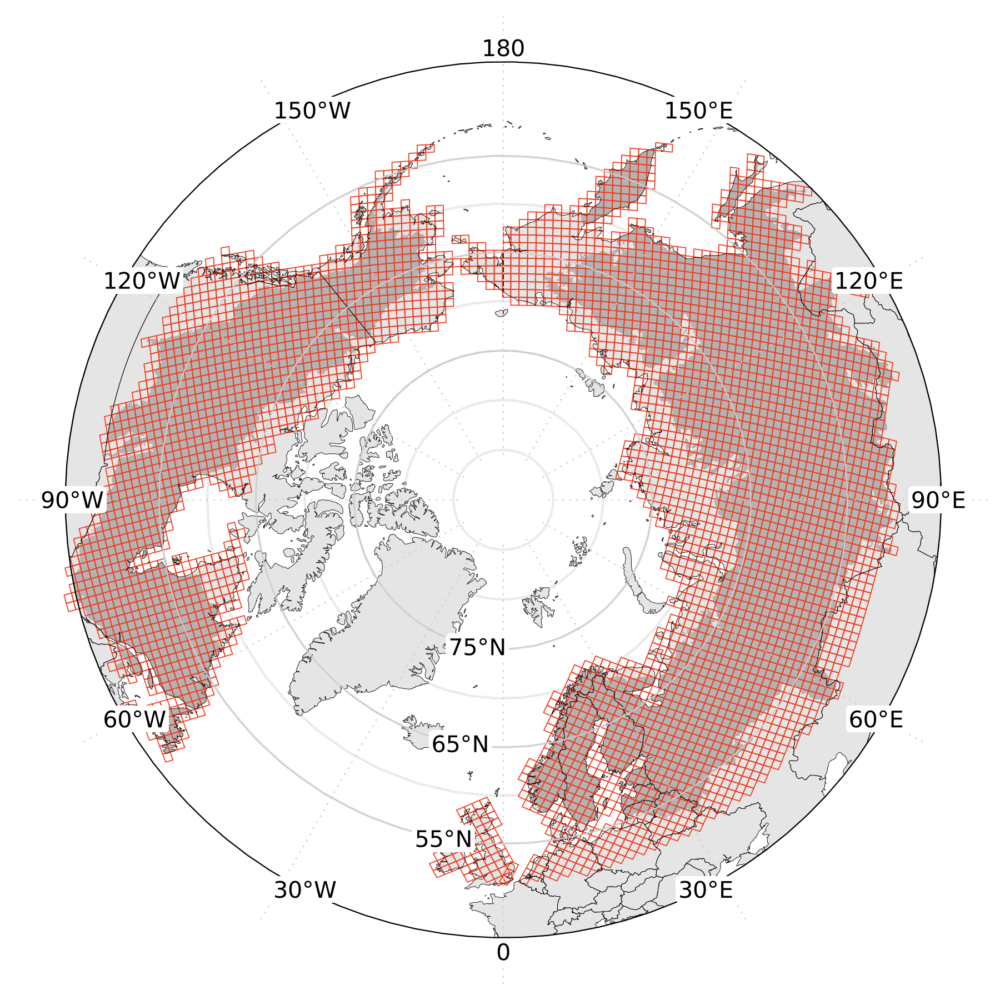

In [28]:
options(repr.plot.width = 6, repr.plot.height = 6, repr.plot.res = 300)

m_boreal_tiles = DO_MAP_BOREAL_SP(MAP_EXTENT=ext,  
                     BOREAL_SHP_FN = wwf_circ_dis_fn,
                     LAYER_LIST = list(geom_polygon(data = boreal_tiles_gcs_DAAC, 
                                                    aes(x = long, y = lat, group = group), size=0.2, fill=NA, color='#f03b20')) #, fill=NA
                    ) + 
    theme(legend.text=element_text(size=rel(0.5))) #+
    #scale_color_brewer(palette = 'Set2') +
    #scale_fill_viridis_d() +
    #guides(fill=guide_legend(title="Tile groups", title.position = "top", label.position = "bottom", keywidth = unit(.5, "cm"), keyheight = unit(.25, "cm"), nrow=2))
m_boreal_tiles

In [29]:
EXPORT_MAPS_PNG_PDF(m_boreal_tiles, OUT_FIGURE_DIR, 'boreal_tiles', '', EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(8,8))

/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_tiles__20250825.png
/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_tiles__20250825.pdf


In [25]:
# options(repr.plot.width = 10, repr.plot.height = 10, repr.plot.res = 300)

# m_boreal_tiles = DO_MAP_BOREAL_SP(MAP_EXTENT=ext,  
#                      BOREAL_SHP_FN = wwf_circ_dis_fn,
#                      LAYER_LIST = list(geom_polygon(data = boreal_tiles_gcs %>% dplyr::filter(tile_num %in% boreal_tile_num_DAAC_list), 
#                                                     aes(x = long, y = lat, group = group), size=0.1, fill=NA, color='black')) #, fill=NA
#                     ) + 
#     theme(legend.text=element_text(size=rel(0.5))) #+
#     #scale_color_brewer(palette = 'Set2') +
#     #scale_fill_viridis_d() +
#     #guides(fill=guide_legend(title="Tile groups", title.position = "top", label.position = "bottom", keywidth = unit(.5, "cm"), keyheight = unit(.25, "cm"), nrow=2))
# m_boreal_tiles

## Export figure: Boreal tiles

In [26]:
OUT_TYPE = 'png'
DATA_NAME_STEM = "boreal_tiles"
EXPORT_TIME_STR = format(Sys.time(), "_%Y%m%d")
path(OUT_FIGURE_DIR, paste0("map_",DATA_NAME_STEM, EXPORT_TIME_STR,".", OUT_TYPE))
for(OUT_TYPE in c('png', 'pdf')){
    map_fn = path(OUT_FIGURE_DIR, paste0("map_",DATA_NAME_STEM, EXPORT_TIME_STR,".", OUT_TYPE))
    print(map_fn)
    ggsave(plot = m_boreal_tiles,
           file = map_fn,
           device = OUT_TYPE, dpi = 300, width = 10, height = 8)
}

/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_tiles_20250825.png

/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_tiles_20250825.png
/projects/my-public-bucket/boreal_AGB/paper_figs/map_boreal_tiles_20250825.pdf


## Map HLS metadata

In [30]:
boreal_tiles_hls_metadata_gcs = shp_fort_join('/projects/my-public-bucket/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2020/HLS_input_params.gpkg', ext, REPROJECT=TRUE)

[1] "Using sf and coercing to Spatial object..."
Reading layer `HLS_input_params' from data source 
  `/projects/my-public-bucket/DPS_tile_lists/HLS/HLS_stack_2023_v1/HLS_H30_2020/HLS_input_params.gpkg' 
  using driver `GPKG'
Simple feature collection with 4956 features and 7 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -6111478 ymin: 1233304 xmax: 6308522 ymax: 10323300
Projected CRS: unnamed


Regions defined for each Polygons


In [31]:
head(boreal_tiles_hls_metadata_gcs %>% as.data.frame())

,long,lat,order,hole,piece,id,group,tile_num,tile_version,tile_group,map_version,n_obs,run_type,num_scenes
,<dbl>,<dbl>,<int>,<lgl>,<fct>,<chr>,<fct>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>
1,6.672362,56.91323,1,FALSE,1,1,1.1,4,version 1,eurasia west,none,226,25_07-01_08-31_2020_2020,19
2,7.483985,57.58611,2,FALSE,1,1,1.1,4,version 1,eurasia west,none,226,25_07-01_08-31_2020_2020,19
3,8.748943,57.14697,3,FALSE,1,1,1.1,4,version 1,eurasia west,none,226,25_07-01_08-31_2020_2020,19
4,7.923729,56.48187,4,FALSE,1,1,1.1,4,version 1,eurasia west,none,226,25_07-01_08-31_2020_2020,19
5,6.672362,56.91323,5,FALSE,1,1,1.1,4,version 1,eurasia west,none,226,25_07-01_08-31_2020_2020,19
6,8.748943,57.14697,1,FALSE,1,2,2.1,9,version 1,eurasia west,none,2637,25_07-01_08-31_2020_2020,73


[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


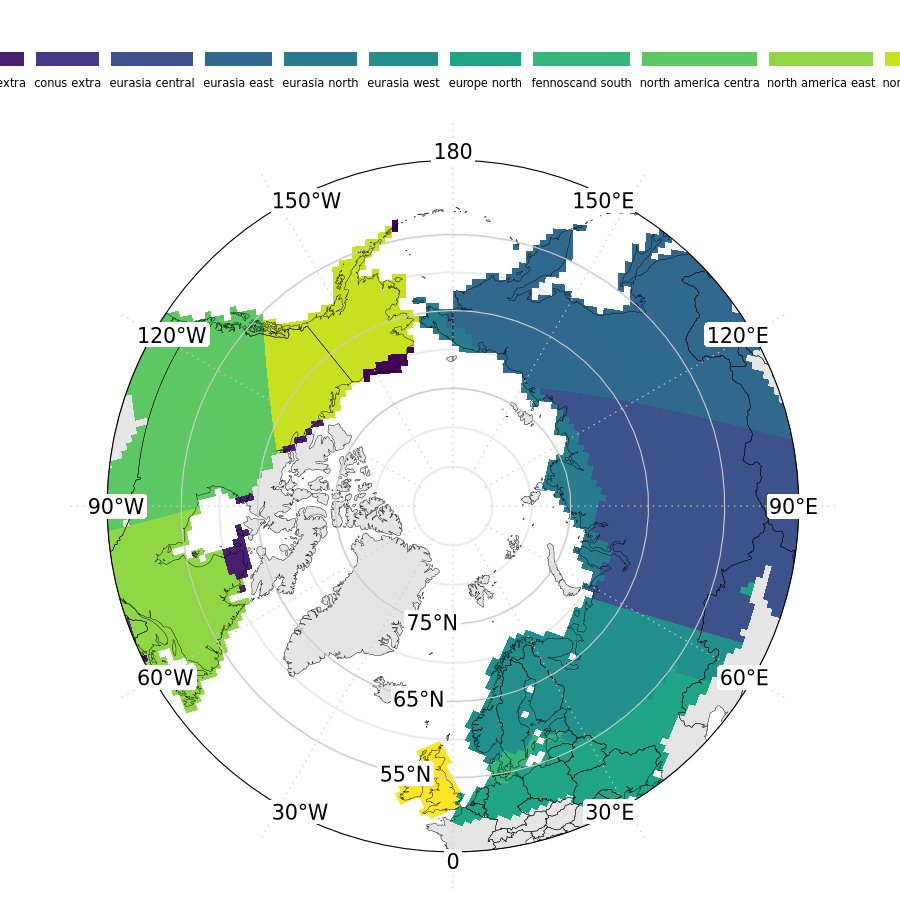

In [32]:
options(repr.plot.width = 6, repr.plot.height = 6, repr.plot.res = 150)

m_boreal_tiles_HLS = DO_MAP_BOREAL_SP(MAP_EXTENT=ext,  
                     BOREAL_SHP_FN = wwf_circ_dis_fn,
                     LAYER_LIST = list(geom_polygon(data = boreal_tiles_hls_metadata_gcs, 
                                                    aes(x = long, y = lat, group = group, fill=tile_group), size=0.1)) #, fill=NA
                    ) + 
    theme(legend.text=element_text(size=rel(0.5))) +
    #scale_color_brewer(palette = 'Set2') +
    scale_fill_viridis_d() +
    guides(fill=guide_legend(title="Tile groups", title.position = "top", label.position = "bottom", keywidth = unit(.5, "cm"), keyheight = unit(.25, "cm"), nrow=1))
m_boreal_tiles_HLS

## Map HLS compositing params

In [33]:
# #hls_params = read.csv("/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS_test_redo/spring2022/HLS_input_params.csv")
# hls_params = read.csv("/projects/shared-buckets/nathanmthomas/DPS_tile_lists/HLS/fall2022/HLS_stack_2022_v2/HLS_input_params.csv")

# This is the final list of HLS tiles that include the fixed (45) tiles
Sys.setenv("AWS_DEFAULT_REGION" = "us-west-2") 
# Read rom s3
hls_params <- aws.s3::s3read_using(read.csv, object = hls_params_fn)

boreal_tiles_gcs_HLS = boreal_tiles_gcs_DAAC %>% 
    dplyr::mutate(tile_num = as.numeric(tile_num)) %>% 
    dplyr::left_join(hls_params, by = c('tile_num' = 'tile_num')) %>%
    unite(HLS_run_name, c("max_cloud","start_month_day","end_month_day"),sep = "\n", remove = FALSE)

In [34]:
head(boreal_tiles_gcs_HLS %>% filter(tile_num == '1000'))

long,lat,order,hole,piece,id,group,tile_num,X,HLS_run_name,max_cloud,start_month_day,end_month_day,start_year,end_year,json_path,num_scenes,run_type
<dbl>,<dbl>,<int>,<lgl>,<fct>,<chr>,<fct>,<dbl>,<int>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>,<chr>


In [35]:
options(repr.plot.width = 6, repr.plot.height = 6, repr.plot.res = 300)
# Show map of HLS compositing params

m_hls_runname = DO_MAP_BOREAL_SP(MAP_EXTENT=ext,  
                     BOREAL_SHP_FN = wwf_circ_dis_fn,
                     LAYER_LIST = list(geom_polygon(data = boreal_tiles_gcs_HLS %>% dplyr::filter(tile_num %in% boreal_tile_num_DAAC_list), 
                                                    aes(x = long, y = lat, group = group, fill=HLS_run_name), size=0.1)
                                      
                                      )
                    ) + 
    theme(legend.title=element_text(size=rel(1.25)), legend.text=element_text(size=rel(0.75))) +
    guides(fill=guide_legend(title="Composite parameters (max cloud % x start date x end date)", title.position = "top", label.position = "bottom", keywidth = unit(.5, "cm"), keyheight = unit(.25, "cm"), nrow=1))+
    #scale_fill_manual(values= c(wes_palette("Zissou1", n = 5), wes_palette("Darjeeling1", n = 5))) 
    scale_fill_brewer(palette='Paired')


m_hls_maxcloud = DO_MAP_BOREAL_SP(MAP_EXTENT=ext,  
                     BOREAL_SHP_FN = wwf_circ_dis_fn,
                     LAYER_LIST = list(geom_polygon(data = boreal_tiles_gcs_HLS %>% dplyr::filter(tile_num %in% boreal_tile_num_DAAC_list), 
                                                    aes(x = long, y = lat, group = group, fill=max_cloud), size=0.1))
                    ) +
    theme(legend.title=element_text(size=rel(1.25)), legend.text=element_text(size=rel(0.75))) +
    scale_fill_viridis_c(option='plasma', direction=-1) +
    guides(fill=guide_colourbar(title="Composite max cloudcover (%)", title.position = "top", label.position = "bottom", keywidth = unit(5, "cm"), keyheight = unit(.25, "cm")))

m_hls_n_scenes = DO_MAP_BOREAL_SP(MAP_EXTENT=ext,  
                     BOREAL_SHP_FN = wwf_circ_dis_fn,
                     LAYER_LIST = list(geom_polygon(data = boreal_tiles_gcs_HLS %>% dplyr::filter(tile_num %in% boreal_tile_num_DAAC_list), 
                                                    aes(x = long, y = lat, group = group, fill=num_scenes), size=0.1))
                    ) +
    theme(legend.title=element_text(size=rel(1.25)), legend.text=element_text(size=rel(0.75))) +
    scale_fill_viridis_c(option='turbo', direction=1) +
    guides(fill=guide_colourbar(title="Per-tile # of scenes for composite", title.position = "top", label.position = "bottom", keywidth = unit(5, "cm"), keyheight = unit(.25, "cm")))



[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


[1] "Using sf and coercing to Spatial object..."
Reading layer `wwf_circumboreal_Dissolve' from data source 
  `/projects/my-public-bucket/databank/arc/wwf_circumboreal_Dissolve.shp' 
  using driver `ESRI Shapefile'
Simple feature collection with 2 features and 4 fields
Geometry type: MULTIPOLYGON
Dimension:     XY
Bounding box:  xmin: -5281040 ymin: -60527.9 xmax: 3959203 ymax: 8747447
Projected CRS: NAD83 / Alaska Albers


Regions defined for each Polygons
Regions defined for each Polygons
Regions defined for each Polygons


In [36]:
PLOT_SF = 0.75

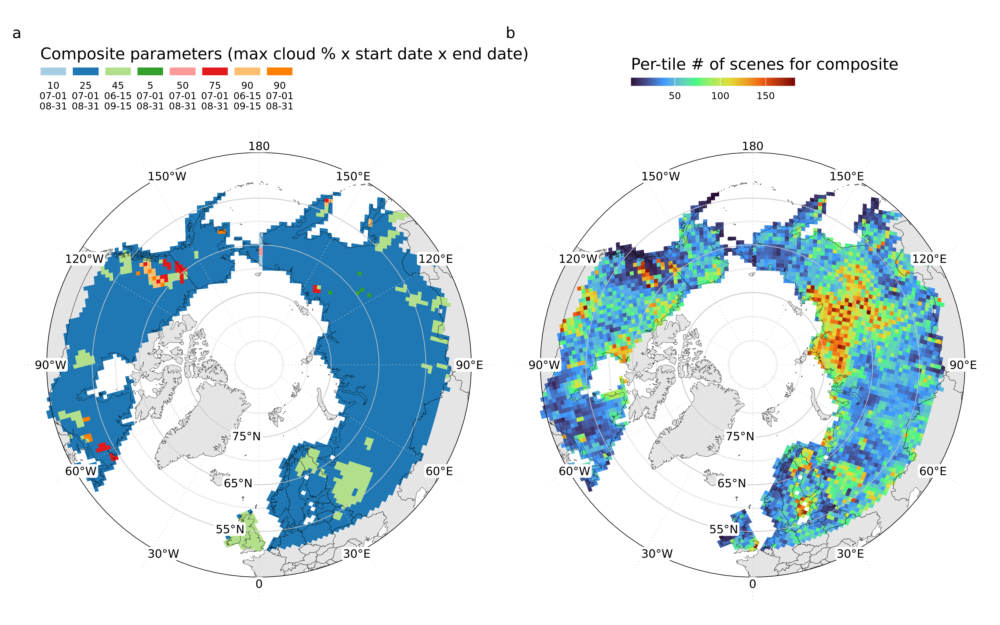

In [37]:
options(repr.plot.width = 16 * PLOT_SF, repr.plot.height = 10 * PLOT_SF, repr.plot.res = 300, warn=-1)

layout = "
AB
"

map_hls_run_scenes = (m_hls_runname | m_hls_n_scenes) +
    plot_layout(design = layout) +
    plot_annotation(tag_levels = 'a') #+ theme(plot.tag = element_text(size = 26))

map_hls_run_scenes

In [38]:
# options(repr.plot.height = 7, repr.plot.width = 14, warn=-1)

# layout = "
# AB
# "

# map_hls_params = (m_hls_runname | m_hls_maxcloud) +
#     plot_layout(design = layout) +
#     plot_annotation(tag_levels = 'a') #+ theme(plot.tag = element_text(size = 26))

# map_hls_params

`summarise()` has grouped output by 'tile_num', 'HLS_run_name'. You can
override using the `.groups` argument.


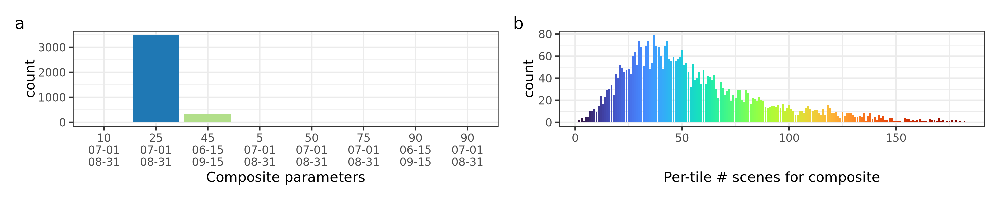

In [39]:
options(repr.plot.height = 2, repr.plot.width = 10, warn=-1)

df = boreal_tiles_gcs_HLS %>% 
    dplyr::filter(tile_num %in% boreal_tile_num_DAAC_list) %>%
    dplyr::group_by(tile_num, HLS_run_name, num_scenes) %>%
    dplyr::summarize(tile_num = mean(tile_num)) # Need to summarize like this to get back to 1 row per tile_num

hist_params = df %>% ggplot() + 
    geom_histogram(aes(x=HLS_run_name, fill=HLS_run_name), stat="count", show.legend=FALSE)+
    scale_fill_brewer(palette='Paired') +
    theme_bw() +
    theme(text=element_text(size=10)) +
    labs(x='Composite parameters')

hist_scenes = df %>% ggplot() + 
    geom_histogram(aes(x=num_scenes, fill=factor(num_scenes)), stat="count", show.legend=FALSE)+
    scale_fill_viridis_d(option='turbo', direction=1) +
    theme_bw() +
    theme(text=element_text(size=10)) +
    labs(x='Per-tile # scenes for composite')

layout = "
AB
"

hist_hls = (hist_params + hist_scenes) +
    plot_layout(design = layout) +
    plot_annotation(tag_levels = 'a') #+ theme(plot.tag = element_text(size = 26))
hist_hls

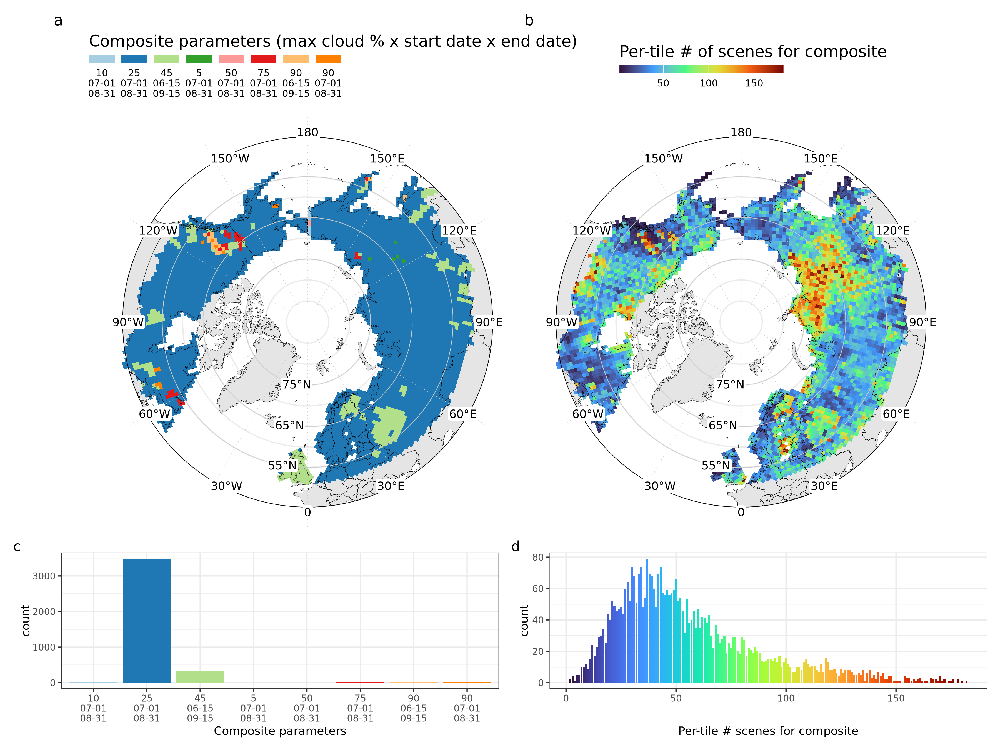

In [41]:
options(repr.plot.width = 16 * PLOT_SF, repr.plot.height = 12 * PLOT_SF, repr.plot.res = 300, warn=-1)

layout = "
AA
AA
AA
BB
"
combined_hls = (map_hls_run_scenes / hist_hls) +
    plot_layout(design = layout) +
    plot_annotation(tag_levels = 'a') #+ theme(plot.tag = element_text(size = 26))

combined_hls

In [42]:
EXPORT_MAPS_PNG_PDF(combined_hls, OUT_FIGURE_DIR, 'HLS_2020', 'composite_params', EXPORT_TIME_STR=format(Sys.time(), "_%Y%m%d"), FIG_DIMS=c(16,12))

/projects/my-public-bucket/boreal_AGB/paper_figs/map_HLS_2020_composite_params_20250825.png
/projects/my-public-bucket/boreal_AGB/paper_figs/map_HLS_2020_composite_params_20250825.pdf


In [48]:
OUT_FIGURE_DIR

[1] "/projects/my-public-bucket/boreal_AGB/paper_figs"

## Export figure: HLS params

In [71]:
OUT_TYPE = 'png'
DATA_NAME_STEM = "HLS_params"
EXPORT_TIME_STR = format(Sys.time(), "_%Y%m%d")
path(OUT_FIGURE_DIR, paste0("map_",DATA_NAME_STEM, EXPORT_TIME_STR,".", OUT_TYPE))
for(OUT_TYPE in c('png', 'pdf')){
    map_fn = path(OUT_FIGURE_DIR, paste0("map_",DATA_NAME_STEM, EXPORT_TIME_STR,".", OUT_TYPE))
    print(map_fn)
    ggsave(plot = combined_hls,
           file = map_fn,
           device = OUT_TYPE, dpi = 300, width = 10, height = 8)
}

/projects/my-public-bucket/boreal_AGB/paper_figs/map_HLS_params_20250421.png

/projects/my-public-bucket/boreal_AGB/paper_figs/map_HLS_params_20250421.png
/projects/my-public-bucket/boreal_AGB/paper_figs/map_HLS_params_20250421.pdf


### Map AGB mean and AGB std
##### Using a raster that gets reprojected

In [72]:
#r = raster('/projects/shared-buckets/alexdevseed/icesat2_boreal_biomass_900m.tif', band=1)
# r_fn = '/projects/shared-buckets/nathanmthomas/DPS_tile_lists/07/AGB_tindex_average_3000m.tif'
# r_fn = '/projects/shared-buckets/nathanmthomas/DPS_tile_lists/AGB/fall2022/map_boreal_2022_v3/11/AGB_tindex_average_3000m.tif'
# r_fn = '/projects/shared-buckets/nathanmthomas/DPS_tile_lists/AGB/winter2023/map_boreal_2022_rh_noground_v4/AGB_tindex_average_4500m.tif'
r_fn = '/projects/my-public-bucket/DPS_tile_lists/BOREAL_MAP/boreal_agb_2024_v6/AGB_H30_2020/Version2_SD/AGB_tindex_average_4500m.tif'
r_agb_mean = raster(r_fn, band=1)
r_agb_std = raster(r_fn, band=2)
names(r_agb_mean) = 'mean_agb'
names(r_agb_std) = 'std_agb'

#plot(r_agb_mean)
#plot(r_agb_std)

#### Convert raster to points, sample

In [73]:
df_list = list()
for(r in c(r_agb_mean, r_agb_std)){
    
    # Convert to df 
    r_p <- sample_frac(data.frame(rasterToPoints(r)), 0.05) #0.01 sample is good for draft work
    
    names(r_p) = c('x','y','value')
    r_p$variable = names(r)
    
    df_list[[names(r)]] = r_p
    rm(r_p)
}
r_p = do.call('rbind', df_list)
rownames(r_p) = NULL
dim(r_p)

[1] 170102      4

#### Do intersection to clip to vector, reproject to GCS, return data frame

In [74]:
r_geo_p =  as_Spatial( 
                    st_intersection(st_as_sf(r_p, coords = c('x','y') , crs = crs_canalb), st_as_sf(boreal_albers) %>% select(REALM)) %>% 
                    st_transform(crs = crs_gcs)
                    )%>% 
            as.data.frame()
# names(r_geo_p)[1] = "value"
names(r_geo_p)[length(names(r_geo_p))-1] = "x"
names(r_geo_p)[length(names(r_geo_p))] = "y"
class(r_geo_p)
tail(r_geo_p)

[1] "data.frame"

,value,variable,REALM,x,y
,<dbl>,<chr>,<chr>,<dbl>,<dbl>
170088,14.768392,std_agb,PA,61.66488,58.70822
170089,4.212684,std_agb,PA,62.96223,55.38567
170090,6.517396,std_agb,PA,124.06750,50.65991
170094,2.841616,std_agb,PA,84.80460,63.99918
170096,13.836082,std_agb,PA,56.92237,59.42964
170098,16.690191,std_agb,PA,41.75840,58.58434


In [ ]:
options(repr.plot.width =8, repr.plot.height =15, repr.plot.res = 300)

map_extent = extent(-180, 180, 45, 90)
min_lat = map_extent[3]
MAX_AGB = 125
MAX_STD = 20
year_agb = '2020'
VERSION = 'v2.3' #summer 2022
dim(r_geo_p)

theme_and_labs = list(
    theme_classic(),
    labs(
        #title="Circumpolar boreal forest aboveground biomass density",
        #subtitle = paste0("c. ",year_agb," 30 m resolution, provisional","\nData sources: ICESat-2, Landsat-8, Copernicus DEM"),
         #caption = paste0("# obs: ", NUM_ATL08_OBS, "\n# obs (night): ", NUM_ATL08_NIGHT_OBS)
         #caption = 'Arctic Boreal Vulnerability Experiment (ABoVE)\nNASA Goddard Space Flight Center\nU. of Maryland Dept. Geographical Sciences'
    )
)

agb_mean_layer_list = list( 
    geom_point(data = sample_frac(r_geo_p %>% dplyr::filter(variable == 'mean_agb'), 1) %>% 
               dplyr::filter(y > min_lat) %>%
               dplyr::mutate(value_adj = case_when(value > MAX_AGB ~ MAX_AGB, 
                                                   TRUE ~ value))
               , aes(x = x, y = y, color = value_adj), size = 0.1, alpha = 0.75),
    scale_color_gradientn(limits = c(0,MAX_AGB), breaks = seq(0,MAX_AGB,25), colours = viridis(10) ),
    guides(color=guide_colourbar(title=expression("Mean of aboveground biomass density ["~Mg~ha^{-1}~"]"), title.position = "top", label.position = "bottom", keywidth = unit(.5, "cm"), keyheight = unit(.25, "cm"))),
    theme_and_labs +
    facet_wrap(~variable)
    )

agb_std_layer_list = list( 
    geom_point(data = sample_frac(r_geo_p %>% dplyr::filter(variable == 'std_agb'), 1) %>% 
               dplyr::filter(y > min_lat) %>%
               dplyr::mutate(value_adj = case_when(value > MAX_STD ~ MAX_STD, 
                                                   TRUE ~ value))
               , aes(x = x, y = y, color = value_adj), size = 0.1, alpha = 0.75),
    scale_color_gradientn(limits = c(0,MAX_STD), breaks = seq(0,MAX_STD,5), colours = plasma(10) ),
    guides(color=guide_colourbar(title=expression("Standard deviation of aboveground biomass density ["~Mg~ha^{-1}~"]"), title.position = "top", label.position = "bottom", keywidth = unit(.5, "cm"), keyheight = unit(.25, "cm"))),
    theme_and_labs +
    facet_wrap(~variable)
    )

m_AGB_mean = DO_MAP_BOREAL_SP(MAP_EXTENT=map_extent, boreal_shp_fn = boreal_shp_fn, LAYER_LIST = agb_mean_layer_list)
m_AGB_std  = DO_MAP_BOREAL_SP(MAP_EXTENT=map_extent, boreal_shp_fn = boreal_shp_fn, LAYER_LIST = agb_std_layer_list)

                             
m_AGB_mean_std = (m_AGB_mean / m_AGB_std) +
          plot_annotation(tag_levels = "a")                   
                             
m_AGB_mean_std

#out_dir = dirname(r_fn)
#DATA_NAME_STEM = "AGB_boreal"
DATA_NAME_STEM = tools::file_path_sans_ext(basename(r_fn))
EXPORT_TIME_STR = format(Sys.time(), "_%Y%m%d")


## Export figure:
AGB mean and AGB std 

In [ ]:
if(TRUE){
    for(OUT_TYPE in c('png', 'pdf')){

        map_fn = path(OUT_FIGURE_DIR, paste0("map_",DATA_NAME_STEM,"_", year_agb, EXPORT_TIME_STR,"_", VERSION, ".", OUT_TYPE))
        print(map_fn)
        ggsave(plot = m_AGB_mean_std,
                   file = map_fn,
                   device = OUT_TYPE, dpi = 300, width = 8, height = 15)
    }
}

## Use patchwork to arrange plots
https://patchwork.data-imaginist.com/

In [42]:
options(repr.plot.width =25, repr.plot.height =10, repr.plot.res = 300)

In [33]:
#m_hls_runname + m_hls_maxcloud + m_rmse + m_r2 + m_ATL08obs + guide_area() + plot_layout(ncol = 2, guides = "collect")
#m_pft

m_AGB | ( (m_hls_runname | m_hls_maxcloud) / (m_rmse | m_r2) / (m_ATL08obs | m_pft) ) + 
#plot_layout(ncol = 3) + 
plot_annotation(tag_levels = "a")

ERROR: Error in m_hls_runname | m_hls_maxcloud: operations are possible only for numeric, logical or complex types


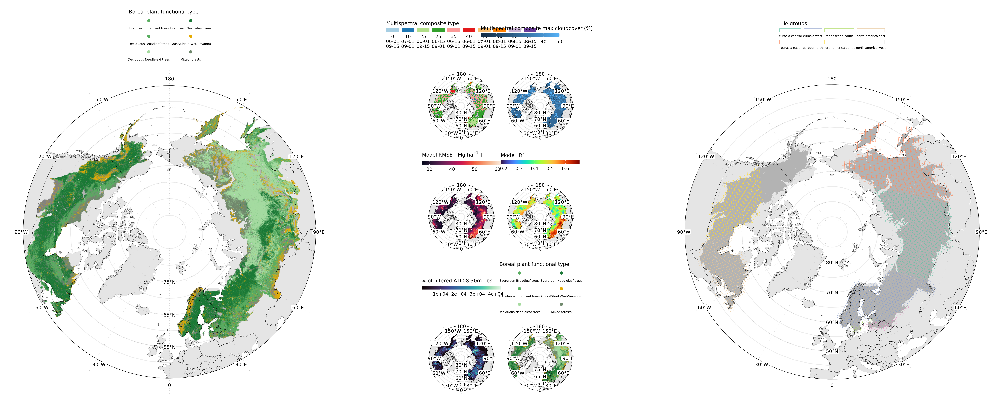

In [43]:
m_pft | ( (m_hls_runname | m_hls_maxcloud) / (m_rmse | m_r2) / (m_ATL08obs | m_pft) ) | m_groups + 
#plot_layout(ncol = 3) + 
plot_annotation(tag_levels = "a")